In [1]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import MultiTissueModel, RelaxationTissueModel
from microtool.utils.unit_registry import unit

microtorch_model = ModelMaker("Ball")





# Wrap each compartment individually, not the combined ModelMaker model.

ball_model = MicrotorchTissueModel(
    microtorch_model,
    parameters={"D": 2},
)



ball_relax = RelaxationTissueModel(ball_model, t2=50e-3 * unit("s"))


ball_model = ball_relax
ball_model["model_D"].optimize = True
ball_model["model_D"].fit_flag = True

ball_model["S0"].optimize = True
ball_model["S0"].fit_flag = True


print(ball_relax)

No YAML configuration found for Ball model.
Falling back to parsing model name for compartments: ['Ball'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  Ball
########### Compartments: ['Ball']
########### Parameter names: [['D']]
########### Parameter ranges: [[[0.001, 3]]]
-----------
Tissue model with 3 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  -------------
model_D                2       1      True        True   (0.001, 3.0)
T2                     0.05    0.001  True        True   (0.0001, 1.0)
S0                     1       1      True        True   (0.0, 2.0)


In [2]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 4
block_size = n_directions + 1  # b0 + n_directions

shell_bvals = [200, 354, 500, 1500]
shell_deltas = [0.0114, 0.0105, 0.02, 0.02]
shell_Deltas = [0.0222, 0.0212, 0.03, 0.03]
initial_te = [0.09, 0.04, 0.06, 0.06]

# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te[i]] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)


# TE and timing: one free value for each 7-measurement shell block.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Gradient magnitude: fix b0, then share one value across each shell's six DW measurements.
b0_mask = b_vals == 0
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

print("TE free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Timing free indices:",
      np.flatnonzero(initial_scheme["DiffusionPulseDuration"].optimize_mask))
print("Gradient free indices:",
      np.flatnonzero(magnitude.optimize_mask))

print(initial_scheme)


Pulse durations: [0.0114 0.0114 0.0114 0.0114 0.0114 0.0114 0.0114 0.0105 0.0105 0.0105
 0.0105 0.0105 0.0105 0.0105 0.02   0.02   0.02   0.02   0.02   0.02
 0.02   0.02   0.02   0.02   0.02   0.02   0.02   0.02  ]
Pulse interval: [0.0222 0.0222 0.0222 0.0222 0.0222 0.0222 0.0222 0.0212 0.0212 0.0212
 0.0212 0.0212 0.0212 0.0212 0.03   0.03   0.03   0.03   0.03   0.03
 0.03   0.03   0.03   0.03   0.03   0.03   0.03   0.03  ]
T 180: 0.006
TE free indices: [ 0  7 14 21]
Timing free indices: [ 0  7 14 21]
Gradient free indices: [ 1  8 15 22]
Acquisition scheme with 28 measurements and 6 scalar parameters. 
total number of optimized parameters is 16:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.01, 0.1)    DiffusionPulseInterval [s] in (0.01, 0.1)    EchoTime [s] in (0.01, 0.1)
-------------------------------------------------  -----------------------------------

In [3]:
signal = ball_model(initial_scheme)
print(signal)

[0.16529889 0.11080316 0.11080316 0.11080316 0.11080316 0.11080316
 0.11080316 0.44932896 0.22135223 0.22135223 0.22135223 0.22135223
 0.22135223 0.22135223 0.30119421 0.11080316 0.11080316 0.11080316
 0.11080316 0.11080316 0.11080316 0.30119421 0.01499558 0.01499558
 0.01499558 0.01499558 0.01499558 0.01499558]


In [4]:
jacobian = ball_model.scaled_jacobian(initial_scheme)
print(jacobian)



[[ 0.00000000e+00  5.95075998e-03  1.65298888e-01]
 [-2.21606308e-02  3.98891363e-03  1.10803156e-01]
 [-2.21606308e-02  3.98891363e-03  1.10803156e-01]
 [-2.21606308e-02  3.98891363e-03  1.10803156e-01]
 [-2.21606308e-02  3.98891363e-03  1.10803156e-01]
 [-2.21606308e-02  3.98891363e-03  1.10803156e-01]
 [-2.21606308e-02  3.98891363e-03  1.10803156e-01]
 [ 0.00000000e+00  7.18926343e-03  4.49328964e-01]
 [-7.83586937e-02  3.54163574e-03  2.21352233e-01]
 [-7.83586937e-02  3.54163574e-03  2.21352233e-01]
 [-7.83586937e-02  3.54163574e-03  2.21352233e-01]
 [-7.83586937e-02  3.54163574e-03  2.21352233e-01]
 [-7.83586937e-02  3.54163574e-03  2.21352233e-01]
 [-7.83586937e-02  3.54163574e-03  2.21352233e-01]
 [ 0.00000000e+00  7.22866109e-03  3.01194212e-01]
 [-5.54015806e-02  2.65927587e-03  1.10803161e-01]
 [-5.54015806e-02  2.65927587e-03  1.10803161e-01]
 [-5.54015806e-02  2.65927587e-03  1.10803161e-01]
 [-5.54015806e-02  2.65927587e-03  1.10803161e-01]
 [-5.54015806e-02  2.65927587e-

/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/torch/autograd/graph.py:1113: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


In [5]:
# import copy
# from microtool.optimize import optimize_scheme

# n_iterations = 1
# current_scheme = copy.deepcopy(initial_scheme)

# solver_options = {
#     "verbose": 2,
#     "maxiter": 1000,
#     "finite_diff_rel_step": 1e-8,
#     # "initial_tr_radius": 0.05
# }

# history = []

# for i in range(n_iterations):
#     print(f"\n{'='*25} Iteration {i + 1}/{n_iterations} {'='*25}")

#     optimized_scheme, res = optimize_scheme(
#         current_scheme,
#         ball_model,
#         noise_variance=0.05,
#         method="trust-constr",
#         solver_options=solver_options,
#     )

#     history.append((optimized_scheme, res))

#     # Feed the result as the initial scheme for the next run
#     current_scheme = copy.deepcopy(optimized_scheme)

# optimal_scheme = current_scheme

In [6]:
import microtool.optimize.methods as methods
from microtool.optimize import optimize_scheme

import numpy as np
from microtool.optimize.loss_functions import compute_loss, gauss_loss


method = methods.SOMA()
optimal_scheme, _ = optimize_scheme(
    initial_scheme, ball_model, noise_variance=0.02, method=method
)

Pulse durations: [0.0114 0.0114 0.0114 0.0114 0.0114 0.0114 0.0114 0.0105 0.0105 0.0105
 0.0105 0.0105 0.0105 0.0105 0.02   0.02   0.02   0.02   0.02   0.02
 0.02   0.02   0.02   0.02   0.02   0.02   0.02   0.02  ]
Pulse interval: [0.0222 0.0222 0.0222 0.0222 0.0222 0.0222 0.0222 0.0212 0.0212 0.0212
 0.0212 0.0212 0.0212 0.0212 0.03   0.03   0.03   0.03   0.03   0.03
 0.03   0.03   0.03   0.03   0.03   0.03   0.03   0.03  ]
T 180: 0.006
[SOMA] Starting Optimization
  Dimension (Nx)     : 16
  Population Size    : 50
  Max Migrations     : 200
  Max Fevals         : 160000
  Jumps per movement : 28
[ 0.078  0.078  0.078  0.078 10.    10.    10.    10.    10.    10.
 10.    10.    10.    10.    10.    10.   ]
[0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Pulse durations: [0.02884097 0.0114     0.0114     0.0114     0.0114     0.0114
 0.0114     0.01903532 0.0105     0.0105     0.0105     0.0105
 0.0105     0.0105     0.08584846 0.02       0.02       0.02
 0.02       0.02       0.02 

ValueError: SOMA could not find a feasible starting point. Check that the constraints and bounds have a feasible intersection.

In [ ]:
import numpy as np

for i, (scheme, res) in enumerate(history):
    print(f"\n{'='*20} Iteration {i + 1} {'='*20}")
    print("\nb-values (s/mm²):")
    print(np.round(scheme.b_values, 2))
    print("\nEcho times (ms):")
    print(np.round(scheme.echo_times * 1e3, 2))


==================== Iteration 1 ====================

b-values (s/mm²):
[  0.     2.16   2.16   2.16   2.16   2.16   2.16   0.     3.03   3.03
   3.03   3.03   3.03   3.03   0.     4.42   4.42   4.42   4.42   4.42
   4.42   0.   622.21 622.21 622.21 622.21 622.21 622.21]

Echo times (ms):
[71.24 71.24 71.24 71.24 71.24 71.24 71.24 12.33 12.33 12.33 12.33 12.33
 12.33 12.33 72.33 72.33 72.33 72.33 72.33 72.33 72.33 54.49 54.49 54.49
 54.49 54.49 54.49 54.49]

==================== Iteration 2 ====================

b-values (s/mm²):
[  0.     2.05   2.05   2.05   2.05   2.05   2.05   0.     3.03   3.03
   3.03   3.03   3.03   3.03   0.     1.04   1.04   1.04   1.04   1.04
   1.04   0.   383.94 383.94 383.94 383.94 383.94 383.94]

Echo times (ms):
[71.25 71.25 71.25 71.25 71.25 71.25 71.25 12.33 12.33 12.33 12.33 12.33
 12.33 12.33 72.32 72.32 72.32 72.32 72.32 72.32 72.32 54.49 54.49 54.49
 54.49 54.49 54.49 54.49]


In [ ]:
print(optimal_scheme)
print(optimal_scheme.b_values)

Acquisition scheme with 28 measurements and 6 scalar parameters. 
total number of optimized parameters is 16:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.078)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.001, 0.1)    DiffusionPulseInterval [s] in (0.001, 0.1)    EchoTime [s] in (0.001, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  --------------------------------------------  --------------------------------------------  ------------------------------
                                     -0                                            2.24761                                       0.982258                                     0.0074298                                    0.0172511                        0.0712472
                                      0.00592361                                  -1.25047              

In [ ]:
print(ball_model(optimal_scheme))

[0.24052213 0.23953833 0.23953833 0.23953833 0.23953833 0.23953833
 0.23953833 0.7813791  0.77665721 0.77665721 0.77665721 0.77665721
 0.77665721 0.77665721 0.23543234 0.23494377 0.23494377 0.23494377
 0.23494377 0.23494377 0.23494377 0.33627423 0.15603084 0.15603084
 0.15603084 0.15603084 0.15603084 0.15603084]


In [ ]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats


# loc is mean and scale is standard deviation
noise_distribution = stats.norm(loc=0, scale=0.02)

# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(
    initial_scheme,
    ball_model,
    noise_distribution,
    n_sim=1000,
    fit_options={"diff_step": 1e-4},
)
simulation.run()
initial = simulation.result

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme)
simulation.run()
optimal = simulation.result

Starting Monte Carlo with 1000 simulations: 100%|██████████| 1000/1000 [00:04<00:00, 202.41it/s]


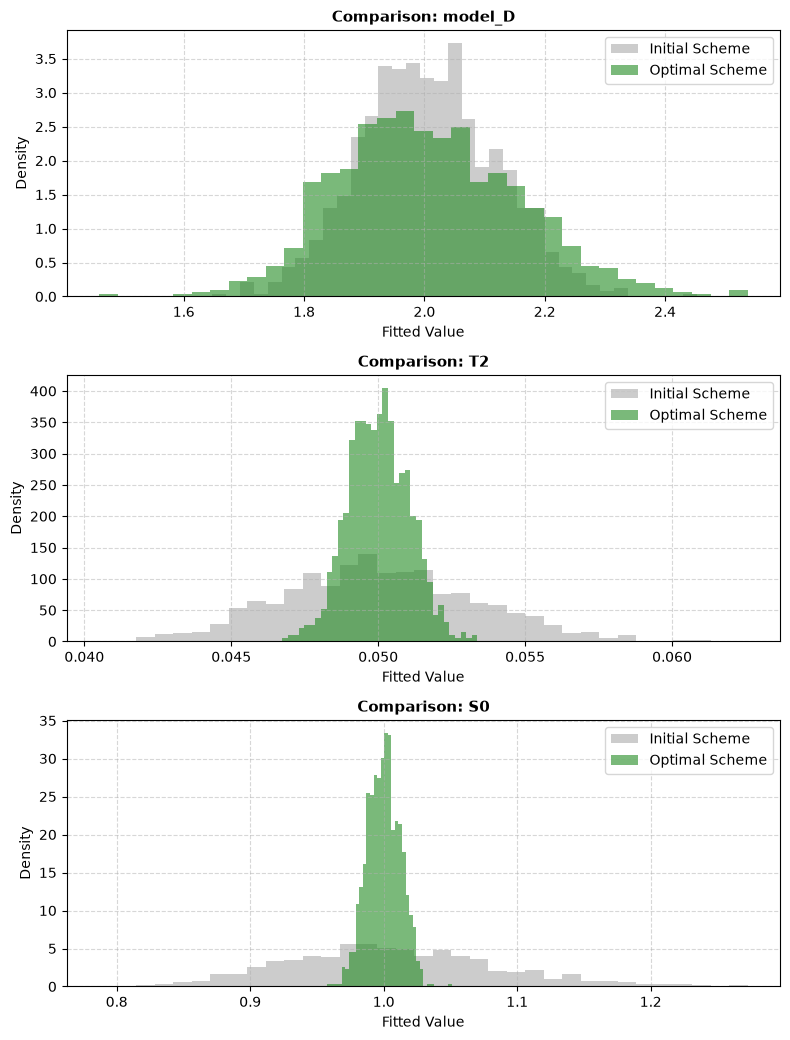

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

df_init = pd.DataFrame(initial)
df_opt = pd.DataFrame(optimal)

common_cols = [c for c in df_opt.columns if c in df_init.columns]

fig, axes = plt.subplots(
    nrows=len(common_cols), ncols=1, figsize=(8, 3.5 * len(common_cols)), squeeze=False
)

for i, col in enumerate(common_cols):
    ax = axes[i, 0]
    ax.hist(df_init[col], bins=35, density=True, alpha=0.4, color="gray", label="Initial Scheme")
    ax.hist(df_opt[col], bins=35, density=True, alpha=0.6, color="forestgreen", label="Optimal Scheme")
    
    ax.set_title(f"Comparison: {col}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Fitted Value")
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()